# Melanoma Screening — VGG16 + Gradio front end

Transfer-learning pipeline over a lesion-image folder in Google Drive, with a Gradio web UI for
checking a single photo.

This is the VGG16 variant of `aimi_melanoma_resnet50.ipynb`. Everything outside the backbone is
identical, so the two can be run against the same data and compared directly. Each writes its own
checkpoint, so they do not overwrite each other.

**Cell order matters.** The front end in the last section reads `model`, `class_names` and the test
metrics from the session, so run the training and evaluation cells first. It will still work on its
own — it falls back to loading the saved `.keras` file from Drive — but the "About the model" panel
won't show the test metrics in that case.

**Data layout:** `Dataset Images` should contain one subfolder per class. Nothing hardcodes the class
count — it is read from the folders — but the screening UI needs to know which folders hold
malignant classes, and finds them by name (see `MAL_IDXS` in the last cell). Subtype labels such as
ALM count as melanoma there.

```
Dataset Images/
    benign/
    malignant/
    <third class>/
```


## Mount Google Drive to access data

In [4]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


## Import functions and perform GPU check

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, roc_auc_score, classification_report,
)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Load and prepare data

`label_mode='int'` gives integer labels (0, 1, 2, ...), which pairs with
`sparse_categorical_crossentropy` during training.


In [6]:
DATA_DIR = '/content/drive/MyDrive/Dataset Images'
IMG_SIZE = (224, 224)
BATCH_SIZE = 16   # drop to 16 or 8 if VGG16 runs out of GPU memory
SEED = 123

# 70% train
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.3,
    subset='training',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
)

# 30% held out -> split into validation + test below
holdout_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.3,
    subset='validation',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

# image_dataset_from_directory shuffles with reshuffle_each_iteration left on, so
# take/skip over it does not cut the same boundary twice: validation and test
# membership drifts every pass. Rebuild both halves from the holdout's fixed file
# list instead, so they are disjoint and identical on every iteration.
import pathlib

holdout_paths = list(holdout_ds.file_paths)   # already seed-shuffled, so each half stays representative
class_to_idx = {n: i for i, n in enumerate(class_names)}
holdout_labels = [class_to_idx[pathlib.Path(p).parent.name] for p in holdout_paths]


def _load_image(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    return tf.image.resize(img, IMG_SIZE), label


def _fixed_ds(paths, labels):
    ds = tf.data.Dataset.from_tensor_slices((list(paths), list(labels)))
    return ds.map(_load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE)


split_at = len(holdout_paths) // 2
val_ds = _fixed_ds(holdout_paths[:split_at], holdout_labels[:split_at])
test_ds = _fixed_ds(holdout_paths[split_at:], holdout_labels[split_at:])

print(f"Train images: {train_ds.cardinality().numpy() * BATCH_SIZE} (approx), "
      f"Val images: {split_at}, Test images: {len(holdout_paths) - split_at}")


Found 17475 files belonging to 3 classes.
Using 12233 files for training.
Found 17475 files belonging to 3 classes.
Using 5242 files for validation.
Classes: ['ALM', 'Benign', 'Melanoma']
Number of classes: 3
Train images: 12240 (approx), Val images: 2621, Test images: 2621


In [7]:
# Check how many images are in each class - useful for spotting imbalance
import pathlib

data_path = pathlib.Path(DATA_DIR)
for name in class_names:
    n = len(list((data_path / name).glob('*')))
    print(f"{name}: {n} images")


ALM: 337 images
Benign: 12839 images
Melanoma: 4299 images


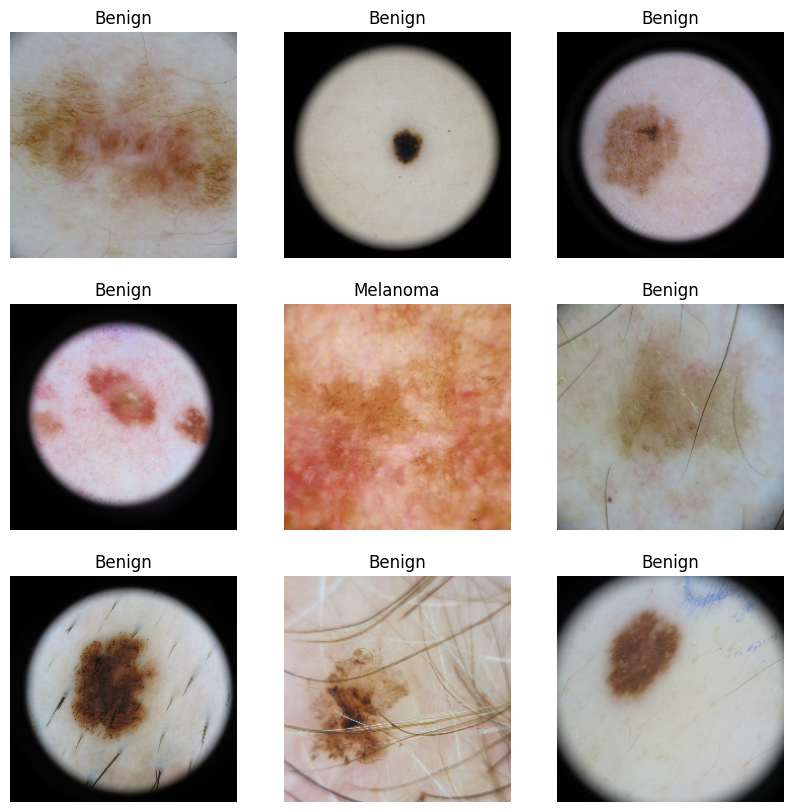

In [8]:
# Preview a few images
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(min(9, images.shape[0])):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")


In [9]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")

AUTOTUNE = tf.data.AUTOTUNE

# Augmentation is applied only to the training set. Validation/test stay untouched
# so evaluation reflects real, unaugmented images.
train_ds = train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y),
    num_parallel_calls=AUTOTUNE,
).prefetch(AUTOTUNE)

val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)


## Load VGG16 base pretrained on ImageNet, frozen

VGG16's convolutional base has ~14.7M parameters, fewer than ResNet50's ~23.6M, but it is the slower
of the two to train: its stack of 3x3 convolutions at full resolution costs roughly 4x the
multiply-accumulates per image. Expect long epochs.

Unlike ResNet50, VGG16 contains no BatchNorm layers, so the `training=False` flag on the base below
only affects dropout. It is kept for consistency and does no harm.


In [10]:
IMG_SHAPE = IMG_SIZE + (3,)

base_model = tf.keras.applications.VGG16(
    input_shape=IMG_SHAPE,
    include_top=False,
    weights='imagenet',
)
base_model.trainable = False  # freeze the pretrained base

base_model.summary()


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

## Classification head implementation

The output layer has one unit per class with a **softmax** activation, so the outputs form a
probability distribution summing to 1.

VGG16's convolutional base ends at 7x7x512, so global average pooling gives a **512-dim** feature
vector — smaller than ResNet50's 2048 and MobileNetV2's 1280.

`vgg16.preprocess_input` converts RGB to BGR and subtracts the ImageNet channel means. VGG16 and
ResNet50 happen to share this Caffe-style preprocessing, so confusing those two is harmless;
substituting MobileNetV2's (which scales to [-1, 1]) is not, and would not raise an error — it would
just train badly.


In [11]:
inputs = tf.keras.Input(shape=IMG_SHAPE)

# VGG16's own preprocessing (RGB -> BGR, ImageNet mean subtraction)
x = tf.keras.applications.vgg16.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)   # 512-dim for VGG16
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

model = tf.keras.Model(inputs, outputs)
model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ input_layer_2[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ input_layer_2[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ vgg16[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 512)       │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 3)         │      1,539 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,716,227 (56.14 MB)

 Trainable params: 1,539 (6.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

## Model training

`sparse_categorical_crossentropy` is the multi-class counterpart to binary crossentropy and expects the
integer labels from `label_mode='int'`.

Keras's `AUC` metric does not accept sparse multi-class labels, so AUC is computed with scikit-learn in
the evaluation section instead of being tracked during training.

If your classes are imbalanced (check the counts printed above), uncomment the `class_weight` block.


In [12]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        '/content/drive/MyDrive/melanoma_vgg16_best.keras',
        monitor='val_loss', save_best_only=True,
    ),
]

#weight the loss by class frequency if your dataset is imbalanced.
from sklearn.utils.class_weight import compute_class_weight
train_labels = np.concatenate([y.numpy() for _, y in train_ds])
weights = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=train_labels)
class_weight = dict(enumerate(weights))
print("Class weights:", class_weight)

EPOCHS = 20

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    # class_weight=class_weight,  # uncomment together with the block above
)


Class weights: {0: np.float64(17.425925925925927), 1: np.float64(0.4526716992303138), 2: np.float64(1.3633121586983172)}
Epoch 1/20
765/765 ━━━━━━━━━━━━━━━━━━━━ 126s 157ms/step - accuracy: 0.6217 - loss: 1.7508 - val_accuracy: 0.7367 - val_loss: 1.0348
Epoch 2/20
765/765 ━━━━━━━━━━━━━━━━━━━━ 66s 86ms/step - accuracy: 0.6872 - loss: 1.2439 - val_accuracy: 0.7711 - val_loss: 0.8396
Epoch 3/20
765/765 ━━━━━━━━━━━━━━━━━━━━ 66s 86ms/step - accuracy: 0.7167 - loss: 1.0096 - val_accuracy: 0.7795 - val_loss: 0.7602
Epoch 4/20
765/765 ━━━━━━━━━━━━━━━━━━━━ 66s 86ms/step - accuracy: 0.7333 - loss: 0.8637 - val_accuracy: 0.7818 - val_loss: 0.7034
Epoch 5/20
765/765 ━━━━━━━━━━━━━━━━━━━━ 66s 86ms/step - accuracy: 0.7389 - loss: 0.7829 - val_accuracy: 0.7837 - val_loss: 0.6377
Epoch 6/20
765/765 ━━━━━━━━━━━━━━━━━━━━ 67s 86ms/step - accuracy: 0.7448 - loss: 0.7140 - val_accuracy: 0.7905 - val_loss: 0.5835
Epoch 7/20
765/765 ━━━━━━━━━━━━━━━━━━━━ 66s 86ms/step - accuracy: 0.7597 - loss: 0.6583 - val_acc

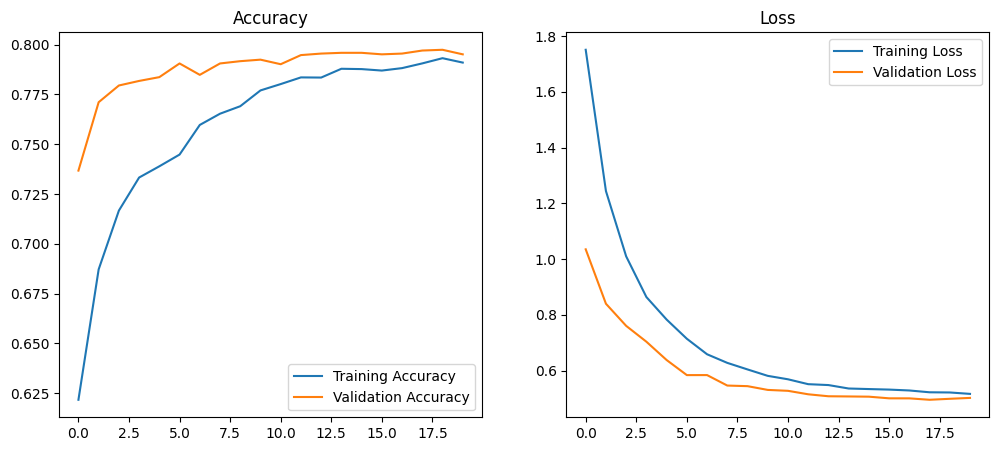

In [13]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(loss))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Loss')

plt.show()


## Model evaluation

With more than two classes a single ROC curve no longer applies. The standard approach is
**one-vs-rest**: each class in turn is treated as positive against all the others, giving one curve and
one AUC per class, plus a macro average.

Labels and predictions are gathered in one pass below, and the recomputed accuracy is printed so it can
be compared against `model.evaluate`. If those two disagree, the per-class numbers and the AUC are
measuring misaligned pairs and should not be read as model quality.


In [14]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")


164/164 ━━━━━━━━━━━━━━━━━━━━ 57s 345ms/step - accuracy: 0.7947 - loss: 0.5088
Test loss: 0.5088 | Test accuracy: 0.7947


In [15]:
# Labels and predictions must be collected in a SINGLE pass over the dataset.
# Reading labels in one pass and calling model.predict(test_ds) in another pairs
# each image's label with a different image's prediction whenever the dataset is
# not perfectly repeatable, which silently destroys every metric below.
y_true, y_pred_prob = [], []
for images, labels in test_ds:
    y_true.append(labels.numpy())
    y_pred_prob.append(model.predict(images, verbose=0))

y_true = np.concatenate(y_true, axis=0)
y_pred_prob = np.concatenate(y_pred_prob, axis=0)   # (n_samples, NUM_CLASSES)
y_pred = np.argmax(y_pred_prob, axis=1)             # highest-probability class

# Sanity check: this must match the accuracy model.evaluate() printed above.
# A large gap means labels and predictions are misaligned, not that the model is poor.
print(f"Accuracy recomputed from paired arrays: {(y_pred == y_true).mean():.4f}")
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))


Accuracy recomputed from paired arrays: 0.7947
              precision    recall  f1-score   support

         ALM       0.39      0.16      0.23        55
      Benign       0.80      0.96      0.88      1939
    Melanoma       0.75      0.34      0.46       627

    accuracy                           0.79      2621
   macro avg       0.65      0.49      0.52      2621
weighted avg       0.78      0.79      0.76      2621



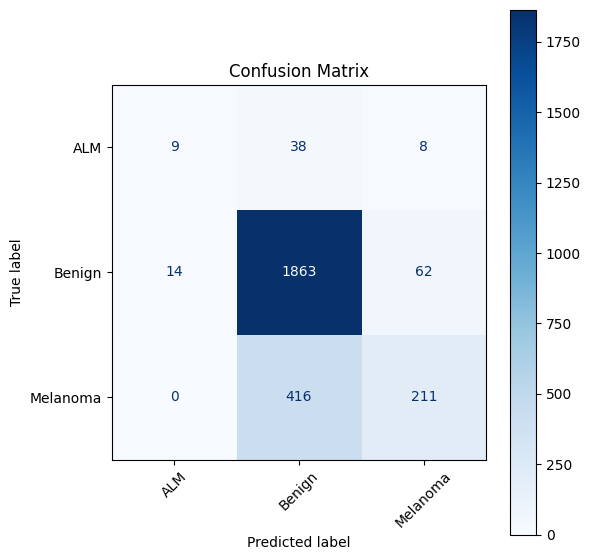

In [16]:
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45)
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()


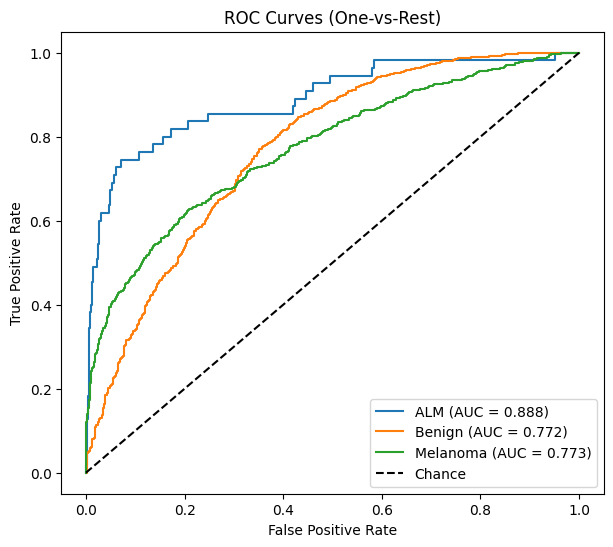

Macro-average one-vs-rest AUC: 0.8110


In [17]:
# One-vs-rest ROC curve: one curve per class
y_true_bin = label_binarize(y_true, classes=np.arange(NUM_CLASSES))

plt.figure(figsize=(7, 6))
for i, name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_prob[:, i])
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc(fpr, tpr):.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves (One-vs-Rest)')
plt.legend(loc='lower right')
plt.show()

macro_auc = roc_auc_score(y_true, y_pred_prob, multi_class='ovr', average='macro')
print(f"Macro-average one-vs-rest AUC: {macro_auc:.4f}")


## Melanoma screening website (Gradio front end)

Run this cell **after** the training and evaluation cells so it picks up `model`, `class_names` and the
test metrics from the session. On its own it falls back to the saved model on Drive.

With more than two classes the UI reports two things: the **predicted class** (highest softmax
probability) and the **melanoma likelihood**, which drives the risk banding.

The likelihood is the summed probability of **every malignant class**, not one of them. This matters
for subtype labels: ALM is acral lentiginous melanoma, a melanoma, so reading only a class literally
named `Melanoma` would show a malignant lesion as low risk. Check the printed `Risk score sums:` line
and correct `MAL_IDXS` by hand if a class is on the wrong side.


In [18]:
# ============================================================
#  Melanoma screening website (Gradio front end) for Google Colab
#  Put this in the LAST cell of the notebook and run it AFTER
#  the training cells (or on its own to use the saved model).
# ============================================================
!pip install -q gradio

import os
import numpy as np
import tensorflow as tf
import gradio as gr
from PIL import Image
from tensorflow.keras import layers

# ------------------------------------------------------------
# 1) CONNECT TO YOUR BACKEND (model + image database on Drive)
# ------------------------------------------------------------
DATA_DIR = '/content/drive/MyDrive/Dataset Images'
MODEL_PATH = '/content/drive/MyDrive/melanoma_vgg16_best.keras'
IMG_SIZE = (224, 224)
SHOW_SIMILAR_CASES = True   # set False to skip building the similar-images index

if not os.path.exists('/content/drive/MyDrive'):
    from google.colab import drive
    drive.mount('/content/drive')

# Use the model trained in this session, or load the saved best model from Drive.
if 'model' not in globals():
    print("Loading saved model from Drive...")
    model = tf.keras.models.load_model(MODEL_PATH)

# Same class order Keras used during training (alphabetical folder names).
if 'class_names' not in globals():
    class_names = sorted(d for d in os.listdir(DATA_DIR)
                         if os.path.isdir(os.path.join(DATA_DIR, d)))
NUM_CLASSES = len(class_names)

# Which classes count as malignant? The risk score sums ALL of them, not just one.
# ALM is acral lentiginous melanoma, a melanoma subtype, so scoring it as
# not-melanoma would report a malignant lesion as low risk.
MALIGNANT_NAMES = {'melanoma', 'alm', 'malignant', 'scc', 'bcc',
                   'acral lentiginous melanoma', 'nodular melanoma',
                   'superficial spreading melanoma', 'lentigo maligna melanoma',
                   'squamous cell carcinoma', 'basal cell carcinoma'}
MALIGNANT_SUBSTRINGS = ('melan', 'malig', 'carcinoma')


def is_malignant(name):
    n = name.strip().lower().replace('_', ' ').replace('-', ' ')
    return n in MALIGNANT_NAMES or any(t in n for t in MALIGNANT_SUBSTRINGS)


MAL_IDXS = [i for i, n in enumerate(class_names) if is_malignant(n)]
if not MAL_IDXS:
    MAL_IDXS = [NUM_CLASSES - 1]
    print(f"WARNING: no class name looks malignant. Falling back to "
          f"'{class_names[MAL_IDXS[0]]}' - set MAL_IDXS by hand if that is wrong.")
elif len(MAL_IDXS) == NUM_CLASSES:
    print("WARNING: every class was read as malignant, so the risk score is always 1.0. "
          "Set MAL_IDXS by hand.")

MAL_LABEL = ' + '.join(class_names[i] for i in MAL_IDXS)
print(f"Classes: {class_names}")
print(f"Risk score sums: {MAL_LABEL}")


def to_model_input(image: Image.Image) -> np.ndarray:
    # Raw 0-255 pixels: your model applies VGG16 preprocess_input itself.
    img = image.convert("RGB").resize(IMG_SIZE)
    return np.expand_dims(np.asarray(img, dtype=np.float32), 0)


def predict_probabilities(image: Image.Image) -> np.ndarray:
    # Softmax vector over all classes, in class_names order.
    return model.predict(to_model_input(image), verbose=0)[0]


# ------------------------------------------------------------
# 2) SIMILAR CASES FROM THE IMAGE DATABASE
#    Uses the VGG16 features to find look-alike images in DATA_DIR.
# ------------------------------------------------------------
db_paths, db_labels, db_feats, feature_extractor = [], None, None, None

if SHOW_SIMILAR_CASES:
    print("Indexing image database for similar cases (one-time, may take a minute)...")
    base = tf.keras.applications.VGG16(input_shape=IMG_SIZE + (3,),
                                       include_top=False, weights='imagenet')
    inp = tf.keras.Input(shape=IMG_SIZE + (3,))
    feat = layers.GlobalAveragePooling2D()(
        base(tf.keras.applications.vgg16.preprocess_input(inp), training=False))
    feature_extractor = tf.keras.Model(inp, feat)

    index_ds = tf.keras.utils.image_dataset_from_directory(
        DATA_DIR, image_size=IMG_SIZE, batch_size=64,
        label_mode='int', shuffle=False)
    db_paths = index_ds.file_paths

    feats, labs = [], []
    for x, y in index_ds:
        feats.append(feature_extractor(x, training=False).numpy())
        labs.append(y.numpy().ravel().astype(int))
    db_feats = np.concatenate(feats)
    db_feats /= np.linalg.norm(db_feats, axis=1, keepdims=True) + 1e-8
    db_labels = np.concatenate(labs)
    print(f"Indexed {len(db_paths)} images.")


def find_similar(image, k=4):
    if feature_extractor is None:
        return []
    q = feature_extractor(to_model_input(image), training=False).numpy()[0]
    q /= np.linalg.norm(q) + 1e-8
    sims = db_feats @ q
    top = np.argsort(-sims)[:k]
    results = []
    for i in top:
        label = class_names[db_labels[i]].capitalize()
        img = Image.open(db_paths[i]).convert("RGB")
        img.thumbnail((300, 300))
        results.append((img, f"{label} | {round(float(sims[i]) * 100)}% similar"))
    return results


# ------------------------------------------------------------
# 3) RESULT LOGIC
# ------------------------------------------------------------
EMPTY_HTML = ("<div class='empty'>Upload a close-up photo of the skin spot, then select "
              "<b>Analyze image</b>.</div>")


def analyze(image):
    if image is None:
        return EMPTY_HTML, None, []

    try:
        probs = predict_probabilities(image)
        similar = find_similar(image)
    except Exception as e:
        return f"<div class='card error'>The model could not process this image: {e}</div>", None, []

    p = float(sum(probs[i] for i in MAL_IDXS))   # melanoma likelihood, all malignant classes
    predicted = class_names[int(np.argmax(probs))].capitalize()

    if p >= 0.5:
        level, cls = "Higher risk", "high"
        advice = ("Features in this image resemble melanoma. Book an appointment with a "
                  "dermatologist or GP soon and show them this spot.")
    elif p >= 0.3:
        level, cls = "Uncertain", "mid"
        advice = ("The result is borderline. Have the spot checked by a doctor, especially "
                  "if it has changed in size, shape or colour.")
    else:
        level, cls = "Lower risk", "low"
        advice = ("No strong melanoma features were detected. Keep monitoring the spot and "
                  "see a doctor if it changes, bleeds or itches.")

    pct = round(p * 100)
    html = f"""
    <div class='card {cls}'>
      <p class='level'>{level}</p>
      <p class='score'>{pct}<span>% melanoma likelihood</span></p>
      <div class='bar'><div style='width:{pct}%'></div></div>
      <p class='predicted'>Closest match: <b>{predicted}</b></p>
      <p class='basis'>Likelihood sums: {MAL_LABEL}</p>
      <p class='advice'>{advice}</p>
    </div>"""
    confidences = {name: float(probs[i]) for i, name in enumerate(class_names)}
    return html, confidences, similar


# Model facts for the "About the model" panel (filled in if training ran this session)
about = [f"VGG16 (ImageNet pretrained) fine-tuned to classify "
         f"{', '.join(c.capitalize() for c in class_names)}."]
about.append(f"Melanoma likelihood is the combined probability of: {MAL_LABEL}.")
if db_paths:
    about.append(f"Image database: {len(db_paths):,} labelled images.")
if 'test_acc' in globals():
    line = f"Held-out test accuracy: {test_acc:.1%}."
    if 'macro_auc' in globals():
        line += f" Macro one-vs-rest AUC: {macro_auc:.3f}."
    about.append(line)
about.append("Similar cases are matched by visual appearance and are shown for context, "
             "not as a diagnosis.")
ABOUT = "\n\n".join(about)

# ------------------------------------------------------------
# 4) DESIGN
# ------------------------------------------------------------
CSS = """
@import url('https://fonts.googleapis.com/css2?family=Source+Serif+4:opsz,wght@8..60,500;8..60,600&family=IBM+Plex+Sans:wght@400;500;600&display=swap');

:root { --ink:#1C2B39; --muted:#5B6B78; --paper:#F4F7F8; --teal:#1F6F78;
        --low:#2E7D5B; --mid:#B7791F; --high:#B23A2E; }

.gradio-container { max-width: 1080px !important; margin: auto !important;
  font-family: 'IBM Plex Sans', system-ui, sans-serif !important; background: var(--paper) !important; }

#hero { padding: 40px 8px 16px; }
#hero h1 { font-family: 'Source Serif 4', Georgia, serif; font-weight: 600;
  font-size: clamp(2rem, 4vw, 2.9rem); line-height: 1.1; color: var(--ink); margin: 0 0 12px; }
#hero p { color: var(--muted); font-size: 1.05rem; max-width: 60ch; line-height: 1.55; margin: 0; }

#lens { border: none !important; background: transparent !important; }
#lens img { border-radius: 50%; aspect-ratio: 1 / 1; object-fit: cover;
  box-shadow: 0 0 0 10px #fff, 0 0 0 11px #cfd9dd; }

#analyze { background: var(--teal) !important; color: #fff !important; border: none !important;
  font-weight: 600; font-size: 1rem; }
#analyze:hover { filter: brightness(1.1); }

.card { background: #fff; border-radius: 14px; padding: 24px 26px; border-left: 6px solid var(--teal); }
.card.low { border-left-color: var(--low); }  .card.mid { border-left-color: var(--mid); }
.card.high { border-left-color: var(--high); }
.card.error { border-left-color: var(--high); color: var(--high); }
.level { font-weight: 600; font-size: 1.1rem; margin: 0; color: var(--ink); }
.low .level { color: var(--low); } .mid .level { color: var(--mid); } .high .level { color: var(--high); }
.score { font-family: 'Source Serif 4', Georgia, serif; font-size: 3.2rem; margin: 6px 0 10px;
  color: var(--ink); line-height: 1; }
.score span { font-family: 'IBM Plex Sans', sans-serif; font-size: 1rem; color: var(--muted); margin-left: 8px; }
.bar { height: 8px; background: #E3EAED; border-radius: 4px; overflow: hidden; }
.bar div { height: 100%; background: var(--teal); transition: width .6s ease; }
.low .bar div { background: var(--low); } .mid .bar div { background: var(--mid); }
.high .bar div { background: var(--high); }
.predicted { color: var(--muted); font-size: .95rem; margin: 14px 0 0; }
.predicted b { color: var(--ink); }
.basis { color: var(--muted); font-size: .8rem; margin: 4px 0 0; }
.advice { color: var(--ink); line-height: 1.55; margin: 10px 0 0; }
.empty { color: var(--muted); padding: 28px; border: 1.5px dashed #c5d1d6; border-radius: 14px;
  text-align: center; line-height: 1.5; }

#similar h3 { font-family: 'Source Serif 4', Georgia, serif; color: var(--ink); margin: 24px 0 4px; }
#similar p { color: var(--muted); margin: 0 0 8px; }

#notice { font-size: .88rem; color: var(--muted); line-height: 1.5;
  border-top: 1px solid #d8e1e5; padding-top: 18px; margin-top: 8px; }
@media (prefers-reduced-motion: reduce) { .bar div { transition: none; } }
"""

THEME = gr.themes.Soft(primary_hue="teal", neutral_hue="slate")

ABCDE = """
Doctors often check moles using the **ABCDE** signs:

- **Asymmetry:** one half doesn't match the other.
- **Border:** edges are ragged, notched or blurred.
- **Colour:** several shades of brown, black, red, white or blue.
- **Diameter:** larger than about 6 mm (a pencil eraser).
- **Evolving:** any change in size, shape, colour, itching or bleeding.
"""

TIPS = """
- Use natural light and hold the camera 10 to 15 cm from the skin.
- Keep the spot centred and in sharp focus.
- Crop out clothing, jewellery and background where possible.
- One spot per photo.
"""

NOTICE = """
**Important:** this tool is for education and research only. It is not a medical device and
cannot diagnose skin cancer. Always have a doctor examine any spot that worries you.
In Australia, you can find a GP or skin check clinic through healthdirect.gov.au.
"""

# ------------------------------------------------------------
# 5) LAYOUT
# ------------------------------------------------------------
GRADIO_6 = int(gr.__version__.split(".")[0]) >= 6
blocks_kwargs = {} if GRADIO_6 else {"css": CSS, "theme": THEME}

with gr.Blocks(title="Skin Spot Check | Melanoma Screening", **blocks_kwargs) as demo:
    gr.HTML("""
      <div id='hero'>
        <h1>Check a skin spot for signs of melanoma</h1>
        <p>Upload a clear photo of a mole or lesion. Our model estimates how closely it
        resembles melanoma, shows similar cases from its image library, and tells you
        what to do next.</p>
      </div>""")

    with gr.Row(equal_height=False):
        with gr.Column(scale=1):
            image_in = gr.Image(type="pil", label="Skin photo", elem_id="lens",
                                sources=["upload", "webcam"], height=360)
            with gr.Row():
                clear_btn = gr.Button("Clear", variant="secondary")
                analyze_btn = gr.Button("Analyze image", elem_id="analyze", variant="primary")
            with gr.Accordion("How to take a good photo", open=False):
                gr.Markdown(TIPS)

        with gr.Column(scale=1):
            result_html = gr.HTML(EMPTY_HTML)
            confidence = gr.Label(label="Model confidence", num_top_classes=NUM_CLASSES)
            with gr.Accordion("Warning signs to look for", open=False):
                gr.Markdown(ABCDE)
            with gr.Accordion("About the model", open=False):
                gr.Markdown(ABOUT)

    gr.HTML("<div id='similar'><h3>Similar cases from the image library</h3>"
            "<p>The closest-looking images in the training database, with their known labels.</p></div>",
            visible=SHOW_SIMILAR_CASES)
    similar_gallery = gr.Gallery(show_label=False, columns=4, height="auto",
                                 visible=SHOW_SIMILAR_CASES)

    gr.Markdown(NOTICE, elem_id="notice")

    analyze_btn.click(analyze, inputs=image_in,
                      outputs=[result_html, confidence, similar_gallery])
    clear_btn.click(lambda: (None, EMPTY_HTML, None, []),
                    outputs=[image_in, result_html, confidence, similar_gallery])

launch_kwargs = {"share": True, "debug": True}
if GRADIO_6:
    launch_kwargs.update(css=CSS, theme=THEME)

demo.launch(**launch_kwargs)


Classes: ['ALM', 'Benign', 'Melanoma']
Risk score sums: ALM + Melanoma
Indexing image database for similar cases (one-time, may take a minute)...
Found 17475 files belonging to 3 classes.
Indexed 17475 images.
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://7bbedd93fe5ea93547.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://7bbedd93fe5ea93547.gradio.live
